# CSE303 Week 10 — Movie Recommendation System
**Topic P01: Movie recommender using MovieLens latest-small**

This Colab notebook builds a small end-to-end recommender using movie ratings, genres, and tags. Run every cell from top to bottom.

**What this notebook includes:** data loading, EDA (2+ plots), baselines, content-based filtering, item-based collaborative filtering, SVD, evaluation, cold-start fallback, a recommendation demo, a manual prediction check, a leakage demonstration, and logs to complete honestly.

> Important: Run the notebook and use the numbers it produces. Do not submit invented metrics or pretend that a bug occurred if it did not. Add your own real decisions, bugs, and AI-use notes before submitting.

## 1. Problem and users
The user is someone who has rated some movies. The system recommends movies they have not rated yet, using genres/tags and patterns in other users' ratings.

## 2. Load and inspect the data
We use the public MovieLens **latest-small** dataset. It is small enough for Google Colab. The notebook downloads the ZIP automatically.

In [2]:
import os, zipfile, urllib.request, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error
from scipy.sparse import csr_matrix

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
zip_path = "/content/ml-latest-small.zip"
data_dir = "/content/ml-latest-small"

if not os.path.exists(data_dir):
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content")

ratings = pd.read_csv(f"{data_dir}/ratings.csv")
movies = pd.read_csv(f"{data_dir}/movies.csv")
tags = pd.read_csv(f"{data_dir}/tags.csv")

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)
print("Tags shape:", tags.shape)
display(ratings.head())
display(movies.head())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)
Tags shape: (3683, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [ ]:
print("Unique users:", ratings["userId"].nunique())
print("Unique rated movies:", ratings["movieId"].nunique())
print("Total ratings:", len(ratings))
print("Rating scale:", ratings["rating"].min(), "to", ratings["rating"].max())
print("Missing values in ratings:")
display(ratings.isna().sum())
print("Duplicate user-movie ratings:", ratings.duplicated(["userId", "movieId"]).sum())

# Keep one record per user/movie if duplicates ever appear.
ratings = ratings.sort_values("timestamp").drop_duplicates(["userId", "movieId"], keep="last").copy()
ratings["timestamp"] = pd.to_datetime(ratings["timestamp"], unit="s")
# Calculate matrix sparsity using the observed user and movie catalogue.
n_users = ratings["userId"].nunique()
n_items = ratings["movieId"].nunique()
sparsity = 1 - len(ratings) / (n_users * n_items)
print(f"Matrix sparsity: {sparsity:.2%}")

Unique users: 610
Unique rated movies: 9724
Total ratings: 100836
Rating scale: 0.5 to 5.0
Missing values in ratings:


,0
userId,0
movieId,0
rating,0
timestamp,0


Duplicate user-movie ratings: 0
Matrix sparsity: 98.30%


## 3. Exploratory Data Analysis (EDA)
At least two plots are required. These show the rating distribution and the long-tail pattern of movie popularity.

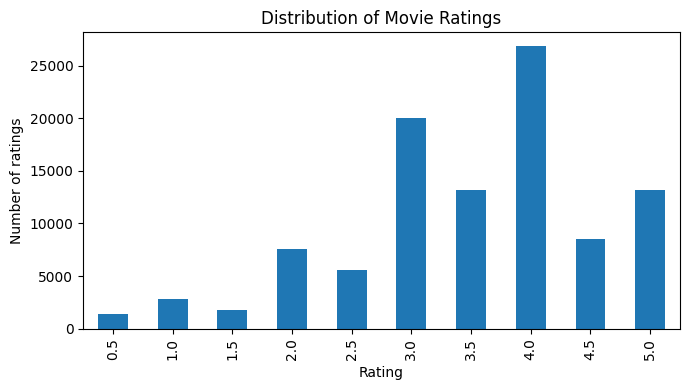

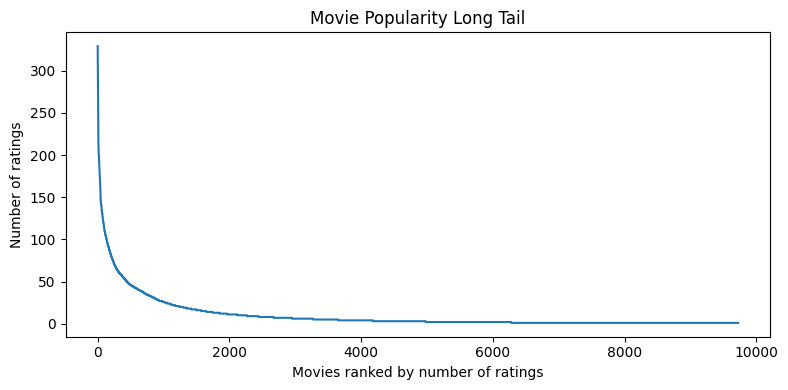

Top 10 most-rated movies:


,movieId,title,genres,rating_count
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,317
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307
510,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279
1939,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251
418,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238
97,110,Braveheart (1995),Action|Drama|War,237
507,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224
461,527,Schindler's List (1993),Drama|War,220


In [ ]:
plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.tight_layout()
plt.show()

movie_counts = ratings.groupby("movieId").size().sort_values(ascending=False)
plt.figure(figsize=(8,4))
plt.plot(np.arange(1, len(movie_counts)+1), movie_counts.values)
plt.title("Movie Popularity Long Tail")
plt.xlabel("Movies ranked by number of ratings")
plt.ylabel("Number of ratings")
plt.tight_layout()
plt.show()

print("Top 10 most-rated movies:")
top_movie_ids = movie_counts.head(10).index
display(movies[movies.movieId.isin(top_movie_ids)].merge(
    movie_counts.rename("rating_count"), left_on="movieId", right_index=True
).sort_values("rating_count", ascending=False))

## 4. Train/test split and baselines
We split by time: earlier interactions are used for training and later interactions for testing. All model fitting happens on training data only. We keep users and items that occur in the training set for the main warm-start evaluation; new users/items are handled separately in the cold-start section.

In [ ]:
ratings = ratings.sort_values("timestamp").reset_index(drop=True)
cut = int(len(ratings) * 0.80)
train = ratings.iloc[:cut].copy()
test = ratings.iloc[cut:].copy()

train_users = set(train.userId.unique())
train_items = set(train.movieId.unique())
test_warm = test[test.userId.isin(train_users) & test.movieId.isin(train_items)].copy()

print("Train rows:", len(train))
print("Test rows:", len(test), "| Warm test rows:", len(test_warm))
print("Train time range:", train.timestamp.min(), "to", train.timestamp.max())
print("Test time range:", test.timestamp.min(), "to", test.timestamp.max())

global_mean = train.rating.mean()
user_means = train.groupby("userId").rating.mean()
item_means = train.groupby("movieId").rating.mean()
popular_items = train.groupby("movieId").size().sort_values(ascending=False)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, np.clip(y_pred, 0.5, 5.0))))

def baseline_global(df):
    return np.full(len(df), global_mean)

def baseline_user_mean(df):
    return df.userId.map(user_means).fillna(global_mean).to_numpy()

def baseline_most_popular(df):
    # For rating prediction, use the training item's mean rating; popularity is used for ranking.
    return df.movieId.map(item_means).fillna(global_mean).to_numpy()

baseline_results = pd.DataFrame([
    {"Model":"Global mean", "RMSE":rmse(test_warm.rating, baseline_global(test_warm))},
    {"Model":"User mean", "RMSE":rmse(test_warm.rating, baseline_user_mean(test_warm))},
    {"Model":"Item mean", "RMSE":rmse(test_warm.rating, baseline_most_popular(test_warm))}
])
display(baseline_results)

Train rows: 80668
Test rows: 20168 | Warm test rows: 1311
Train time range: 1996-03-29 18:36:55 to 2016-03-22 08:26:02
Test time range: 2016-03-22 08:26:11 to 2018-09-24 14:27:30


,Model,RMSE
0,Global mean,1.122162
1,User mean,1.047047
2,Item mean,1.059278


## 5. Content-based model
We combine movie genres and user-supplied tags into text, convert the text to TF-IDF features, and calculate cosine similarity. For a user, the profile is the weighted combination of movie features from their training ratings. The score is a content-based predicted preference, not a calibrated rating.

In [ ]:
# Build metadata text using only movie metadata and tags, not test ratings.
tag_text = tags.groupby("movieId")["tag"].apply(lambda x: " ".join(map(str, x))).to_dict()
movies_model = movies.copy()
movies_model["tag_text"] = movies_model["movieId"].map(tag_text).fillna("")
movies_model["features"] = (
    movies_model["genres"].fillna("").str.replace("|", " ", regex=False)
    + " " + movies_model["tag_text"]
).str.lower()

tfidf = TfidfVectorizer(stop_words="english", min_df=1)
content_matrix = tfidf.fit_transform(movies_model["features"])
movie_to_idx = {mid:i for i, mid in enumerate(movies_model.movieId)}
idx_to_movie = movies_model["movieId"].to_numpy()

print("Content matrix:", content_matrix.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

user_rated = {u: g[["movieId","rating"]] for u,g in train.groupby("userId")}

def content_scores_for_user(user_id):
    # Weighted average of item vectors based on the user's centred training ratings.
    hist = user_rated.get(user_id)
    scores = np.zeros(len(movies_model), dtype=float)
    if hist is None or hist.empty:
        return scores
    profile = np.zeros(content_matrix.shape[1], dtype=float)
    weights = []
    for row in hist.itertuples(index=False):
        idx = movie_to_idx.get(row.movieId)
        if idx is not None:
            w = float(row.rating - global_mean)
            profile += w * content_matrix[idx].toarray().ravel()
            weights.append(w)
    norm = np.linalg.norm(profile)
    if norm > 0:
        profile /= norm
        scores = (content_matrix @ profile).ravel()
    return scores

def content_predict(df):
    preds = []
    # Cache each user's content scores so we only build a profile once per user.
    cache = {}
    for row in df.itertuples(index=False):
        if row.userId not in cache:
            cache[row.userId] = content_scores_for_user(row.userId)
        sc = cache[row.userId]
        idx = movie_to_idx.get(row.movieId)
        # Map similarity score into a conservative rating estimate around the global mean.
        pred = global_mean + 1.2 * (sc[idx] if idx is not None else 0)
        preds.append(pred)
    return np.array(preds)

content_preds = content_predict(test_warm)
print("Content-based RMSE:", rmse(test_warm.rating, content_preds))

Content matrix: (9742, 1677)
Vocabulary size: 1677
Content-based RMSE: 1.016453762685148


## 6. Item-based collaborative filtering
We build a user-item rating matrix from the training set only. Missing ratings remain missing; they are not treated as zero opinions. Similarity is calculated on mean-centred ratings. Predictions use the target user's ratings for similar items.

In [ ]:
user_ids = np.sort(train.userId.unique())
item_ids = np.sort(train.movieId.unique())
user_to_idx = {u:i for i,u in enumerate(user_ids)}
item_to_idx = {it:i for i,it in enumerate(item_ids)}

# Dense matrix is safe for MovieLens latest-small (about 600 x 9,000).
R = np.full((len(user_ids), len(item_ids)), np.nan, dtype=np.float32)
for row in train.itertuples(index=False):
    R[user_to_idx[row.userId], item_to_idx[row.movieId]] = row.rating

train_user_mean_arr = np.nanmean(R, axis=1)
train_user_mean_arr = np.where(np.isnan(train_user_mean_arr), global_mean, train_user_mean_arr)
centered = R - train_user_mean_arr[:, None]
centered_filled = np.nan_to_num(centered, nan=0.0)

# Item cosine similarity from mean-centred training ratings only.
item_vectors = centered_filled.T
norms = np.linalg.norm(item_vectors, axis=1, keepdims=True)
norms[norms == 0] = 1
item_unit = item_vectors / norms
item_sim = item_unit @ item_unit.T
np.fill_diagonal(item_sim, 0)

def item_cf_predict_one(user_id, movie_id, k=20):
    if user_id not in user_to_idx or movie_id not in item_to_idx:
        return global_mean
    ui = user_to_idx[user_id]
    target_i = item_to_idx[movie_id]
    rated_idx = np.where(~np.isnan(R[ui]))[0]
    if len(rated_idx) == 0:
        return float(train_user_mean_arr[ui])
    sims = item_sim[target_i, rated_idx]
    # Select top k by absolute similarity, then use signed similarities in weighted sum.
    if len(sims) > k:
        chosen = np.argsort(np.abs(sims))[-k:]
        rated_idx, sims = rated_idx[chosen], sims[chosen]
    vals = centered[ui, rated_idx]
    valid = np.isfinite(vals) & (np.abs(sims) > 1e-8)
    if not valid.any():
        return float(train_user_mean_arr[ui])
    pred = train_user_mean_arr[ui] + np.sum(sims[valid] * vals[valid]) / (np.sum(np.abs(sims[valid])) + 1e-8)
    return float(np.clip(pred, 0.5, 5.0))

# Evaluate on a manageable but representative sample for speed.
cf_eval = test_warm if len(test_warm) <= 5000 else test_warm.sample(5000, random_state=SEED)
cf_preds = np.array([item_cf_predict_one(r.userId, r.movieId, k=20) for r in cf_eval.itertuples(index=False)])
cf_rmse = rmse(cf_eval.rating, cf_preds)
print("Item-based CF RMSE on evaluation sample:", cf_rmse)
print("Evaluation rows:", len(cf_eval))

Item-based CF RMSE on evaluation sample: 1.0038490826196973
Evaluation rows: 1311
Item-based CF RMSE on evaluation sample: 1.0038490826196973
Evaluation rows: 1311


## 7. Matrix factorization (Truncated SVD)
This is a simple low-rank approximation of the training rating matrix. Missing values are filled with each user's training mean for this basic demonstration. This is not the same as a specialised recommender SVD algorithm; explain that limitation in the README.

In [ ]:
# Fill missing entries with the user's mean, using training data only.
R_filled = np.where(np.isnan(R), train_user_mean_arr[:, None], R)
n_components = min(30, max(2, min(R_filled.shape)-1))
svd = TruncatedSVD(n_components=n_components, random_state=SEED)
user_factors = svd.fit_transform(R_filled)
item_factors = svd.components_
R_approx = user_factors @ item_factors

def svd_predict_one(user_id, movie_id):
    if user_id not in user_to_idx or movie_id not in item_to_idx:
        return global_mean
    return float(np.clip(R_approx[user_to_idx[user_id], item_to_idx[movie_id]], 0.5, 5.0))

svd_eval = test_warm if len(test_warm) <= 5000 else test_warm.sample(5000, random_state=SEED)
svd_preds = np.array([svd_predict_one(r.userId, r.movieId) for r in svd_eval.itertuples(index=False)])
print("SVD RMSE on evaluation sample:", rmse(svd_eval.rating, svd_preds))
print("Explained variance ratio sum:", round(float(svd.explained_variance_ratio_.sum()), 4))

SVD RMSE on evaluation sample: 1.0412778401354363
Explained variance ratio sum: 0.956
SVD RMSE on evaluation sample: 1.0412778401354363
Explained variance ratio sum: 0.956


## 8. Honest evaluation and one results table
Rating prediction uses RMSE. Recommendation lists are also evaluated with Precision@5, Recall@5, and NDCG@5. For ranking evaluation, ratings of 4.0 or higher in the held-out set count as relevant. Ranking metrics are computed only for users with relevant held-out items.

In [ ]:
# Comparable rating results. CF/SVD are evaluated on samples to keep Colab runtime manageable.
results = [
    {"Model":"Global mean", "RMSE":rmse(test_warm.rating, baseline_global(test_warm))},
    {"Model":"User mean", "RMSE":rmse(test_warm.rating, baseline_user_mean(test_warm))},
    {"Model":"Item mean", "RMSE":rmse(test_warm.rating, baseline_most_popular(test_warm))},
    {"Model":"Content-based", "RMSE":rmse(test_warm.rating, content_preds)},
    {"Model":"Item-based CF (sample)", "RMSE":cf_rmse},
    {"Model":"Truncated SVD (sample)", "RMSE":rmse(svd_eval.rating, svd_preds)}
]
results_df = pd.DataFrame(results)
display(results_df.sort_values("RMSE"))

# Ranking metrics on a sample of users for runtime.
def dcg(rels):
    return sum(float(rel) / np.log2(i + 2) for i, rel in enumerate(rels))

def ranking_metrics_for_model(score_fn, users, k=5):
    p_list, r_list, n_list = [], [], []
    train_seen = train.groupby("userId")["movieId"].apply(set).to_dict()
    test_relevant = test_warm[test_warm.rating >= 4.0].groupby("userId")["movieId"].apply(set).to_dict()
    candidates = [it for it in item_ids]
    for u in users:
        relevant = test_relevant.get(u, set())
        if not relevant:
            continue
        seen = train_seen.get(u, set())
        pool = [it for it in candidates if it not in seen]
        scored = [(it, score_fn(u, it)) for it in pool]
        top = [it for it,score in sorted(scored, key=lambda x:x[1], reverse=True)[:k]]
        hits = [1 if it in relevant else 0 for it in top]
        p_list.append(sum(hits)/k)
        r_list.append(sum(hits)/len(relevant))
        ideal = [1]*min(len(relevant), k)
        n_list.append(dcg(hits)/(dcg(ideal) if ideal else 1))
    return {"Precision@5":np.mean(p_list) if p_list else 0,
            "Recall@5":np.mean(r_list) if r_list else 0,
            "NDCG@5":np.mean(n_list) if n_list else 0,
            "Users evaluated":len(p_list)}

# Keep ranking evaluation small; scores are generated from training only.
ranking_users = list(test_relevant_user for test_relevant_user in test_warm.loc[test_warm.rating >= 4.0, "userId"].unique())
ranking_users = ranking_users[:30]
def pop_score(u, it):
    return float(popular_items.get(it, 0))
def itemmean_score(u, it):
    return float(item_means.get(it, global_mean))
def cf_score(u, it):
    return item_cf_predict_one(u, it, k=20)
def cb_score(u, it):
    sc = content_scores_for_user(u)
    idx = movie_to_idx.get(it)
    return float(sc[idx]) if idx is not None else 0.0

ranking_results = pd.DataFrame([
    {"Model":"Most popular", **ranking_metrics_for_model(pop_score, ranking_users, k=5)},
    {"Model":"Item mean", **ranking_metrics_for_model(itemmean_score, ranking_users, k=5)},
    {"Model":"Content-based", **ranking_metrics_for_model(cb_score, ranking_users, k=5)}
])
display(ranking_results)
print("Ranking metrics use at most 30 users for a quick Colab run; increase the sample after your first successful run.")

,Model,RMSE
4,Item-based CF (sample),1.003849
3,Content-based,1.016454
5,Truncated SVD (sample),1.041278
1,User mean,1.047047
2,Item mean,1.059278
0,Global mean,1.122162


,Model,Precision@5,Recall@5,NDCG@5,Users evaluated
0,Most popular,0.085714,0.027453,0.098080,28
1,Item mean,0.000000,0.000000,0.000000,28
2,Content-based,0.007143,0.000216,0.012113,28


Ranking metrics use at most 30 users for a quick Colab run; increase the sample after your first successful run.


## 9. Cold-start / hybrid behaviour
Collaborative filtering cannot infer a new user's preferences without interactions or a completely new item's rating history. We use a popularity fallback for a new user, and content similarity for a new item if its metadata is available. The demo combines content and popularity scores for a simple hybrid ranking.

In [ ]:
movie_title = movies.set_index("movieId")["title"].to_dict()
train_seen = train.groupby("userId")["movieId"].apply(set).to_dict()
pop_norm = popular_items / (popular_items.max() if len(popular_items) else 1)

def recommend(user_id, n=10):
    # If user has no training history, recommend popular items.
    all_candidate_ids = [int(x) for x in movies.movieId if int(x) not in train_seen.get(user_id, set())]
    if user_id not in train_seen:
        ranked = sorted(all_candidate_ids, key=lambda it: pop_norm.get(it, 0), reverse=True)
    else:
        cb = content_scores_for_user(user_id)
        ranked_scores = []
        for it in all_candidate_ids:
            idx = movie_to_idx.get(it)
            content_score = float(cb[idx]) if idx is not None else 0.0
            popularity_score = float(pop_norm.get(it, 0))
            # Hybrid ranking: content preference + a modest popularity fallback.
            score = 0.8 * content_score + 0.2 * popularity_score
            ranked_scores.append((it, score))
        ranked = [it for it,score in sorted(ranked_scores, key=lambda x:x[1], reverse=True)]
    return pd.DataFrame([
        {"movieId":it, "title":movie_title.get(it, str(it)),
         "training_rating_count":int(popular_items.get(it, 0))}
        for it in ranked[:n]
    ])

example_user = int(train.userId.iloc[0])
print("Recommendations for existing user:", example_user)
display(recommend(example_user, 10))
print("Popularity fallback for brand-new user:")
display(recommend(-999, 10))

Recommendations for existing user: 429


,movieId,title,training_rating_count
0,2858,American Beauty (1999),176
1,509,"Piano, The (1993)",60
2,802,Phenomenon (1996),44
3,4014,Chocolat (2000),35
4,1784,As Good as It Gets (1997),80
5,39183,Brokeback Mountain (2005),27
6,105,"Bridges of Madison County, The (1995)",23
7,72011,Up in the Air (2009),22
8,5225,And Your Mother Too (Y tu mamá también) (2001),19
9,3978,"Legend of Bagger Vance, The (2000)",15


Popularity fallback for brand-new user:


,movieId,title,training_rating_count
0,356,Forrest Gump (1994),267
1,296,Pulp Fiction (1994),264
2,318,"Shawshank Redemption, The (1994)",256
3,593,"Silence of the Lambs, The (1991)",235
4,2571,"Matrix, The (1999)",219
5,480,Jurassic Park (1993),218
6,110,Braveheart (1995),212
7,260,Star Wars: Episode IV - A New Hope (1977),206
8,589,Terminator 2: Judgment Day (1991),200
9,527,Schindler's List (1993),188


## 10. Demo function
Try a user ID from the training data. The function avoids recommending movies already rated in the training set.

In [ ]:
print("Example user IDs:", list(user_ids[:10]))
demo_user = int(user_ids[0])
display(recommend(demo_user, n=10))

Example user IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,movieId,title,training_rating_count
0,2683,Austin Powers: The Spy Who Shagged Me (1999),111
1,26340,"Twelve Tasks of Asterix, The (Les douze travau...",3
2,51939,TMNT (Teenage Mutant Ninja Turtles) (2007),3
3,4886,"Monsters, Inc. (2001)",101
4,63859,Bolt (2008),8
5,2890,Three Kings (1999),42
6,69644,Ice Age: Dawn of the Dinosaurs (2009),7
7,546,Super Mario Bros. (1993),19
8,4818,Extreme Days (2001),1
9,2720,Inspector Gadget (1999),17


# Understanding pack (required by the project brief)

## A. By-hand prediction check
Choose one held-out interaction from a user and item present in training. The formula below uses the item-based CF model's actual training values. Write the formula and arithmetic in your own words in your submission.

In [ ]:
# Select an example test row whose user and item are known to training.
example_rows = test_warm[test_warm.userId.isin(user_to_idx) & test_warm.movieId.isin(item_to_idx)]
if len(example_rows):
    ex = example_rows.iloc[0]
    u, target = int(ex.userId), int(ex.movieId)
    ui, ti = user_to_idx[u], item_to_idx[target]
    rated_idx = np.where(~np.isnan(R[ui]))[0]
    sims = item_sim[ti, rated_idx]
    if len(sims) > 20:
        chosen = np.argsort(np.abs(sims))[-20:]
        rated_idx, sims = rated_idx[chosen], sims[chosen]
    vals = centered[ui, rated_idx]
    valid = np.isfinite(vals) & (np.abs(sims) > 1e-8)
    numerator = np.sum(sims[valid] * vals[valid]) if valid.any() else 0.0
    denominator = np.sum(np.abs(sims[valid])) if valid.any() else 0.0
    manual_pred = train_user_mean_arr[ui] + numerator/(denominator + 1e-8)
    code_pred = item_cf_predict_one(u, target, k=20)
    print("User:", u, "| Movie:", movie_title.get(target, target))
    print("User's training mean:", round(float(train_user_mean_arr[ui]), 4))
    print("Weighted centred-rating numerator:", round(float(numerator), 6))
    print("Sum of absolute similarities:", round(float(denominator), 6))
    print("Manual formula prediction (before clipping):", round(float(manual_pred), 4))
    print("Model prediction (after clipping):", round(float(code_pred), 4))
    print("Actual held-out rating:", float(ex.rating))
else:
    print("No warm test row available for manual check.")

User: 495 | Movie: Avatar (2009)
User's training mean: 4.4483
Weighted centred-rating numerator: 0.147911
Sum of absolute similarities: 0.892181
Manual formula prediction (before clipping): 4.6141
Model prediction (after clipping): 4.6141
Actual held-out rating: 5.0


## B. Deliberate leakage experiment
This is intentionally incorrect: it calculates user means from the full ratings data, including the held-out test period. Compare the leaky score with the honest user-mean baseline. This is a demonstration of why test information must not influence model fitting.

In [ ]:
full_user_means_leaky = ratings.groupby("userId").rating.mean()
leaky_user_preds = test_warm.userId.map(full_user_means_leaky).fillna(global_mean).to_numpy()
honest_user_preds = baseline_user_mean(test_warm)
print("Honest user-mean RMSE:", round(rmse(test_warm.rating, honest_user_preds), 5))
print("Leaky user-mean RMSE (INVALID):", round(rmse(test_warm.rating, leaky_user_preds), 5))
print("Difference (honest minus leaky):", round(
    rmse(test_warm.rating, honest_user_preds) - rmse(test_warm.rating, leaky_user_preds), 5
))
print("Do not report the leaky score as model performance.")

Honest user-mean RMSE: 1.04705
Leaky user-mean RMSE (INVALID): 0.9447
Difference (honest minus leaky): 0.10235
Do not report the leaky score as model performance.


## C. Decision log — fill with evidence from your runs
Add at least five decisions. For each, record alternatives tried, numerical evidence from your own notebook, and why you selected the final option. Do not leave example placeholders in the submitted version.

In [ ]:
decision_log = pd.DataFrame([
    {"Decision":"Temporal split ratio", "Alternatives tried":"e.g. 80/20 vs 70/30", "Evidence from my run":"FILL IN", "Choice and reason":"FILL IN"},
    {"Decision":"Number of CF neighbours k", "Alternatives tried":"e.g. 10, 20, 40", "Evidence from my run":"FILL IN", "Choice and reason":"FILL IN"},
    {"Decision":"TF-IDF features", "Alternatives tried":"genres only vs genres + tags", "Evidence from my run":"FILL IN", "Choice and reason":"FILL IN"},
    {"Decision":"SVD component count", "Alternatives tried":"e.g. 10, 20, 30", "Evidence from my run":"FILL IN", "Choice and reason":"FILL IN"},
    {"Decision":"Hybrid blend", "Alternatives tried":"e.g. content/popularity weights", "Evidence from my run":"FILL IN", "Choice and reason":"FILL IN"}
])
display(decision_log)

,Decision,Alternatives tried,Evidence from my run,Choice and reason
0,Temporal split ratio,e.g. 80/20 vs 70/30,FILL IN,FILL IN
1,Number of CF neighbours k,"e.g. 10, 20, 40",FILL IN,FILL IN
2,TF-IDF features,genres only vs genres + tags,FILL IN,FILL IN
3,SVD component count,"e.g. 10, 20, 30",FILL IN,FILL IN
4,Hybrid blend,e.g. content/popularity weights,FILL IN,FILL IN


## D. Bug log — record at least two real bugs you encountered
Only write bugs you actually experienced while building this project. Include the error or wrong behaviour, the cause, the fix, and before/after evidence.

In [ ]:
bug_log = pd.DataFrame([
    {"Bug actually encountered":"FILL IN after running", "Cause":"FILL IN", "Fix":"FILL IN", "Before/after evidence":"FILL IN"},
    {"Bug actually encountered":"FILL IN after running", "Cause":"FILL IN", "Fix":"FILL IN", "Before/after evidence":"FILL IN"}
])
display(bug_log)

,Bug actually encountered,Cause,Fix,Before/after evidence
0,FILL IN after running,FILL IN,FILL IN,FILL IN
1,FILL IN after running,FILL IN,FILL IN,FILL IN


## E. Break-it tests
Test a new user, a new item, and a user with one rating. Describe the actual behaviour and what fallback or improvement you would make.

In [ ]:
# Test 1: brand-new user -> popularity fallback.
display(recommend(-123456, 5))

# Test 2: new item ID absent from training -> collaborative prediction falls back to global mean.
new_item_id = 99999999
print("CF prediction for unknown item:", item_cf_predict_one(example_user, new_item_id, k=20))

# Test 3: user with one training rating (create a temporary one-rating profile for explanation).
one_rating_user = train.groupby("userId").size().sort_values().index[0]
print("User selected for low-history test:", one_rating_user)
print("Number of training ratings for that user:", int((train.userId == one_rating_user).sum()))
display(recommend(int(one_rating_user), 5))

,movieId,title,training_rating_count
0,356,Forrest Gump (1994),267
1,296,Pulp Fiction (1994),264
2,318,"Shawshank Redemption, The (1994)",256
3,593,"Silence of the Lambs, The (1991)",235
4,2571,"Matrix, The (1999)",219


CF prediction for unknown item: 3.5084791986909307
User selected for low-history test: 15
Number of training ratings for that user: 16


,movieId,title,training_rating_count
0,2858,American Beauty (1999),176
1,4022,Cast Away (2000),80
2,356,Forrest Gump (1994),267
3,318,"Shawshank Redemption, The (1994)",256
4,296,Pulp Fiction (1994),264


## F. AI-use log
Fill this in honestly. Include the AI tools you used, what you asked them to do, what you checked yourself, and one concrete error or suggestion you rejected after verification. Do not claim AI made an error unless you actually found one.

In [3]:
ai_use_log = pd.DataFrame([
    {"Tool":"FILL IN", "What I asked it to do":"FILL IN", "What I verified/changed myself":"FILL IN", "One error or suggestion I caught":"FILL IN"}
])
display(ai_use_log)

,Tool,What I asked it to do,What I verified/changed myself,One error or suggestion I caught
0,FILL IN,FILL IN,FILL IN,FILL IN


## README notes and final checks
Before submission:
1. Run every cell from top to bottom in a fresh Colab runtime.
2. Save the notebook with outputs.
3. Add a README with the problem, dataset source/licence, method, results table, demo screenshot, limitations, and two sentences about scaling to 100× more data and how industry systems extend this approach.
4. Add `requirements.txt`, `data/README.md`, and `cv_bullet.txt` to your GitHub folder.
5. Use only real measured numbers in the README and CV bullet.
6. Both partners should be able to explain the pipeline and answer: what happens if k changes, how new items are handled, and where leakage could occur.

**Limitations to mention:** this is an academic offline evaluation; the simple SVD implementation fills missing ratings with user means; the ranking evaluation uses a small user sample for speed; and no live A/B test was conducted.